# Hands-on 2 · Applying VLMs to archival images



**Goal:** use one VLM to suggest archival subject terms from the image, then run the same VLM with catalog context and compare its suggestions. The notebook uses a public Library of Congress photograph. No API key is needed.

**Run:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. The open 3B VLM downloads on first run; allow several minutes and preferably preload before teaching. A GPU is required for this 30-minute exercise. Model suggestions still need review.



Sources: [LOC item record](https://www.loc.gov/pictures/item/2017729954/) · [Wikimedia Commons file](https://commons.wikimedia.org/wiki/File:African_american_sharecropper_kids.jpg) · [Qwen2.5-VL-3B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct). Review rights for other images before reuse.

In [ ]:
%pip -q install "transformers>=4.52,<5" "accelerate>=1.0,<2" "pillow>=10,<12" "requests>=2.31,<3" "pandas>=2,<3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 45.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import io, re, torch, requests, pandas as pd
from PIL import Image
from IPython.display import display
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
if not torch.cuda.is_available():
    raise RuntimeError("Select a T4 GPU in Colab: Runtime > Change runtime type > T4 GPU")
print("GPU:", torch.cuda.get_device_name(0))
processor = AutoProcessor.from_pretrained(MODEL_ID, max_pixels=768 * 28 * 28)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, device_map="auto", attn_implementation="sdpa"
)
model.eval()

def ask_vlm(image, question, max_new_tokens=140):
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": question}
    ]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], images=[image], padding=True, return_tensors="pt").to(model.device)
    with torch.inference_mode():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.batch_decode(
        output[:, inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True, clean_up_tokenization_spaces=False,
    )[0].strip()

GPU: Tesla T4


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

## 1. Load and inspect the archival image

This Ben Shahn photograph of children in Little Rock, Arkansas is held by the Library of Congress. The same image is available from Wikimedia Commons, which this cell tries first; the LOC image server is the fallback. **No manual upload is needed.** The LOC catalog title contains a historical racial term. Quote it only when examining the original record, and review language used in any new description. Keep the title hidden during the image-only analysis.

Downloaded from: https://upload.wikimedia.org/wikipedia/commons/2/22/African_american_sharecropper_kids.jpg
Catalog source: https://www.loc.gov/pictures/item/2017729954/


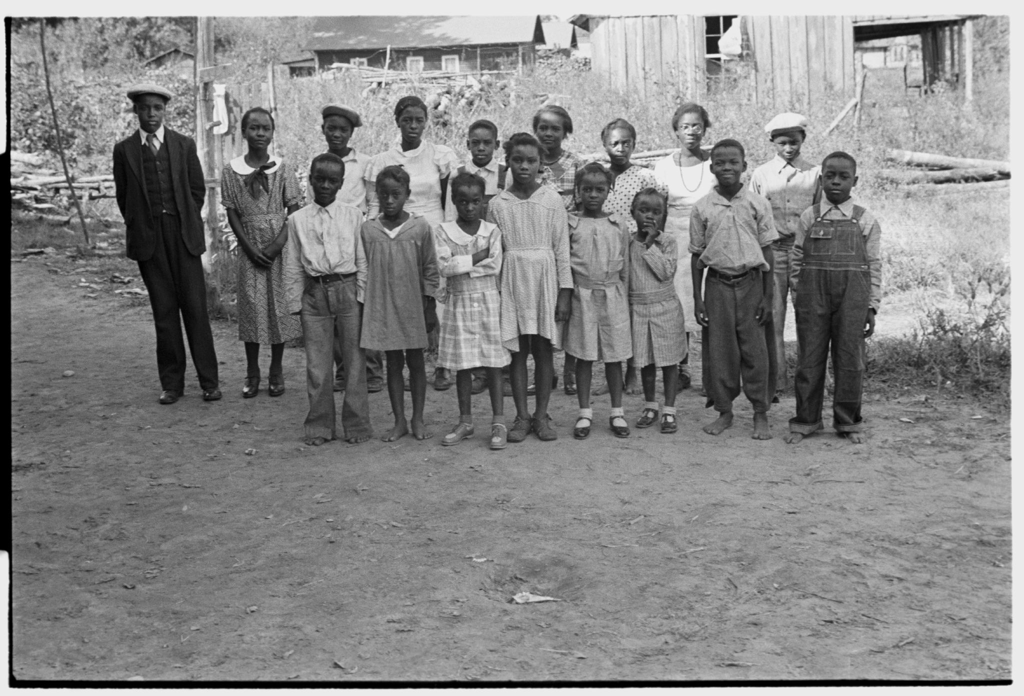

In [ ]:
ITEM_URL = "https://www.loc.gov/pictures/item/2017729954/"
IMAGE_URLS = [
    "https://upload.wikimedia.org/wikipedia/commons/2/22/African_american_sharecropper_kids.jpg",
    "https://tile.loc.gov/storage-services/service/pnp/fsa/8a16000/8a16100/8a16182v.jpg",
]
headers = {"User-Agent": "Mozilla/5.0", "Referer": "https://www.loc.gov/"}
image_bytes = None
for url in IMAGE_URLS:
    try:
        response = requests.get(url, headers=headers, timeout=20)
        response.raise_for_status()
        image_bytes = response.content
        print("Downloaded from:", url)
        break
    except requests.RequestException as exc:
        print(f"Image server unavailable ({exc}); trying the next option.")
if image_bytes is None:
    raise RuntimeError("Both public image hosts are unavailable. Check network access and rerun this cell.")
image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
image.thumbnail((1024, 1024))
print("Catalog source:", ITEM_URL)
display(image)

## 2. Zero-shot visual description

The model sees the image only. Mark anything in its answer that is not visually supported, especially exact identity, place, date, occupation, or historical circumstances.

In [ ]:
zero_shot = ask_vlm(image, "Describe what is visible in this photograph in two short sentences.")
print(zero_shot)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


A group of children and adults stand on a dirt road in front of a wooden building.


## 3. Let the VLM select image-supported terms

The model sees **only the image** here. Give it a short list of candidate terms and require exact terms on one output line. Exclude place and occupation because the photograph alone cannot establish them. The labels are a teaching vocabulary, not verified LCSH/AAT/TGM authority terms. The code checks the response format; it does not invent a selection if the VLM fails to answer.

In [ ]:
visual_candidates = ["Children", "Group portraits", "Wooden buildings", "Schools", "Automobiles"]
visual_prompt = f"""Look at the photograph. Choose 1 to 3 terms that the image visibly supports.
Allowed terms: {', '.join(visual_candidates)}.
Reply in exactly one line: Visual terms: term1; term2
Copy terms exactly. Do not choose a term merely because it is listed. No other text."""
visual_raw = ask_vlm(image, visual_prompt, max_new_tokens=100)
print("VLM response:", visual_raw)

def selected_terms(raw, field, allowed, fallback_index=0, expected_lines=1):
    lines = [line.strip() for line in raw.splitlines() if line.strip()]
    line = next((line for line in lines if line.lower().startswith(field.lower() + ":")), None)
    if line is None and len(lines) == expected_lines:
        line = lines[fallback_index]  # unlabeled outputs follow the requested line order
    if line is None:
        return [], []
    line = re.sub(r"^(visual terms|catalog-only terms)\s*:\s*", "", line, flags=re.I)
    lookup = {term.casefold(): term for term in allowed}
    chosen, unknown = [], []
    for piece in line.split(";"):
        piece = piece.strip().strip(" .-•")
        if not piece or piece.casefold() in {"none", "n/a"}:
            continue
        term = lookup.get(piece.casefold())
        if term and term not in chosen:
            chosen.append(term)
        elif not term:
            unknown.append(piece)
    return chosen, unknown

visual_terms, visual_unknown = selected_terms(visual_raw, "Visual terms", visual_candidates)
print("Valid image-only terms:", visual_terms)
if visual_unknown:
    print("Not in candidate list:", visual_unknown)
if not visual_terms:
    print("No valid selection found. Inspect the raw response above and retry with a simpler prompt.")

VLM response: Children; Group portraits; Wooden buildings
Valid image-only terms: ['Children', 'Group portraits', 'Wooden buildings']


**Generate subject terms without a candidate list.**

Now ask the same VLM to propose its own terms. This is open vocabulary generation: it may surface a useful idea missing from the list, but it may also invent context or use wording that is not an authorized subject heading. Compare these terms with the constrained selection above.

In [ ]:
free_prompt = """Look at the photograph and propose 3 to 5 short subject terms for an archive.
Use only details visible in the image. Do not guess place, date, identity, occupation, or relationships.
Return only the terms, separated by semicolons. Do not use a candidate list or add an explanation."""
free_raw = ask_vlm(image, free_prompt, max_new_tokens=110)
print("VLM freely generated terms:", free_raw)

# This only separates the model's words; it does not validate their meaning or authority status.
free_text = re.sub(r"^(subject terms|terms)\s*:\s*", "", free_raw.strip(), flags=re.I)
free_terms = []
for part in re.split(r"[;\n]+", free_text):
    term = re.sub(r"^\s*(?:[-*]|\d+[.)])\s*", "", part).strip().strip(" .")
    if term and term not in free_terms:
        free_terms.append(term)
print("Separated for review:", free_terms)

VLM freely generated terms: African American family; rural community; childhood; traditional clothing; outdoor portrait
Separated for review: ['African American family', 'rural community', 'childhood', 'traditional clothing', 'outdoor portrait']


## 4. Generate an enriched archival description

Give the same VLM the image plus facts from the LOC record. Its task is to write a new one-sentence description and propose subject terms, with an evidence tag for each. This is the multimodal synthesis step: visible details should come from the image, while place, date, and the sharecropping context must come from the record. The original catalog title uses historical wording; the new description should use respectful current wording. Review every claim against its stated source.

In [ ]:
catalog_title = "Colored children of sharecroppers, Little Rock, Arkansas"  # historical LOC wording
catalog_date = "October 1935"
catalog_creator = "Ben Shahn"
record_facts = f"""LOC record title: {catalog_title}
LOC date: {catalog_date}
LOC photographer: {catalog_creator}"""
description_prompt = f"""Study the photograph and these record facts:
{record_facts}

Write one NEW, neutral archival description in one or two sentences. Describe the visible people and setting,
then include the verified place and date from the record. Do not copy the catalog title as a sentence.
Do not infer race, social status, feelings, relationships, or historical activity from appearance.
Do not repeat the historical racial wording in the title. Return only the description."""
enriched_description = ask_vlm(image, description_prompt, max_new_tokens=120)
print("New draft description:\n", enriched_description)

terms_prompt = f"""Study the same photograph and these LOC record facts:
{record_facts}

Propose four SHORT subject phrases for indexing this photograph. Include phrases for clearly visible content
and phrases supported by the LOC record. Make your own phrases; no candidate list is provided.
Put each phrase on its own line and end the line with exactly one evidence tag in square brackets:
[image] for visible content, [catalog] for record-only context, or [both] when both support it.
Do not output instructions, placeholder words, a title, a sentence-length explanation, or a confidence score.
Do not treat the photographer as a subject. Do not infer social status or identities from appearance."""
context_raw = ask_vlm(image, terms_prompt, max_new_tokens=160)
print("VLM subject suggestions:\n", context_raw)

def parse_tagged_terms(raw):
    proposed = []
    for line in raw.splitlines():
        for piece in line.split(";"):
            match = re.fullmatch(
                r"\s*(?:[-*]|\d+[.)])?\s*(.+?)\s*\[(image|catalog|both)\]\s*",
                piece, flags=re.I,
            )
            if not match:
                continue
            phrase = re.sub(r"^(terms|subject terms)\s*:\s*", "", match.group(1), flags=re.I).strip(" .:-")
            if not phrase or re.fullmatch(r"(?:term|phrase|subject phrase)\d*", phrase, re.I):
                continue  # never treat a copied placeholder as a real subject term
            tagged = (phrase, match.group(2).lower())
            if tagged not in proposed:
                proposed.append(tagged)
    return proposed

context_terms = parse_tagged_terms(context_raw)
print("Terms and claimed evidence:", context_terms or "No usable tagged terms; review the raw model output")

New draft description:
 The photograph depicts a group of children and adults standing outdoors on a dirt path in front of wooden structures. The individuals are dressed in various styles of clothing, including dresses, overalls, and suits. The setting appears to be rural, with sparse vegetation and a simple, rustic environment. The image is dated October 1935 and was taken by Ben Shahn.
VLM subject suggestions:
 [Colored children of sharecroppers] [Little Rock, Arkansas] [October 1935] [Ben Shahn]
[Sharecroppers' family] [Diverse clothing styles] [African American community] [Historical photograph]
Terms and claimed evidence: No usable tagged terms; review the raw model output


## 5. Human review

Compare the VLM's two runs. A term may move when catalog context is added. The table records where the term came from, but it is **not an automatic accuracy score**. Check the image, record, and authorized vocabulary before accepting anything. Empty selections should stay visible as model failures, not be silently filled in.

In [ ]:
review = pd.DataFrame(
    [{"run": "image only", "candidate": term, "claimed source": "image", "human decision": "review"}
     for term in visual_terms]
    + [{"run": "free generation", "candidate": term, "claimed source": "VLM image only; unverified", "human decision": "review"}
       for term in free_terms]
    + [{"run": "image + catalog", "candidate": term, "claimed source": "image", "human decision": "review"}
       for term in context_visual_terms]
    + [{"run": "image + catalog", "candidate": term, "claimed source": "LOC title", "human decision": "review"}
       for term in context_catalog_terms]
)
display(review)

,run,candidate,claimed source,human decision
0,image only,Children,image,review
1,image only,Group portraits,image,review
2,image only,Wooden buildings,image,review
3,free generation,African American family,VLM image only; unverified,review
4,free generation,rural community,VLM image only; unverified,review
5,free generation,childhood,VLM image only; unverified,review
6,free generation,traditional clothing,VLM image only; unverified,review
7,free generation,outdoor portrait,VLM image only; unverified,review
8,image + catalog,Children,image,review
9,image + catalog,Group portraits,image,review


## 6. Participant exercise and wrap-up

1. Change one candidate term or simplify the step 3 prompt, then rerun. Did the VLM's exact selection change?
2. Sort the review table into **topic**, **geography**, and **form/genre** as in the slides. Which candidates need information beyond the image?
3. For a real collection, discuss where copyright/privacy checks, authority matching, and cataloger approval would enter the workflow. Avoid uploading restricted collection images to public services without institutional permission.

**Optional own image:** replace the first URL in `IMAGE_URLS` with a stable public URL for an image you are permitted to use, then update the catalog source and review notes. The model runs in the Colab runtime, which is a cloud service.